In [ ]:
!pip -q install catboost
!pip -q install xgboost
!pip -q install lightgbm

In [ ]:
import pandas as pd
import numpy as np
from scipy import stats
from sklearn.metrics import mean_squared_error

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.compose import make_column_transformer, ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, StandardScaler, OneHotEncoder

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, VotingRegressor, StackingRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
import lightgbm as lgb
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.metrics import accuracy_score

In [ ]:
df_train = pd.read_csv('/content/train.csv')
df_test = pd.read_csv('/content/test.csv')

In [ ]:
df_train.columns

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
       'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
       'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive

In [ ]:
df_train.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


# **Outliers**

In [ ]:
df_train.dtypes[df_train.dtypes != 'object']

,0
Id,int64
MSSubClass,int64
LotFrontage,float64
LotArea,int64
OverallQual,int64
OverallCond,int64
YearBuilt,int64
YearRemodAdd,int64
MasVnrArea,float64
BsmtFinSF1,int64


In [ ]:
def view_outliers(df_train):
  outliers = {}
  num_cols = df_train.select_dtypes(include=['int64', 'float64']).columns

  for col in num_cols:
    Q1 = df_train[col].quantile(0.25)
    Q3 = df_train[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outlier_mask = (df_train[col] < lower_bound) | (df_train[col] > upper_bound)
    outliers[col] = outlier_mask.sum()


  return pd.Series(outliers).sort_values(ascending=False)


In [ ]:
view_outliers(df_train)

,0
EnclosedPorch,208
BsmtFinSF2,167
OverallCond,125
ScreenPorch,116
MSSubClass,103
MasVnrArea,96
LotFrontage,88
BsmtHalfBath,82
OpenPorchSF,77
LotArea,69


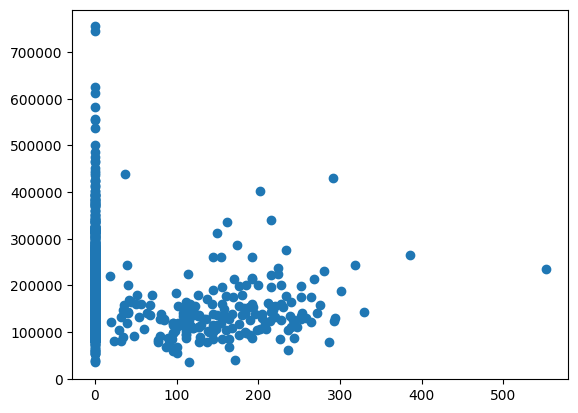

In [ ]:
plt.scatter(x='EnclosedPorch', y='SalePrice', data=df_train)

In [ ]:
df_train.query('EnclosedPorch > 350')
#198, 748

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
197,198,75,RL,174.0,25419,Pave,NaN,Reg,Lvl,AllPub,...,512,Ex,GdPrv,NaN,0,3,2006,WD,Abnorml,235000
747,748,70,RM,65.0,11700,Pave,Pave,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2009,WD,Normal,265979


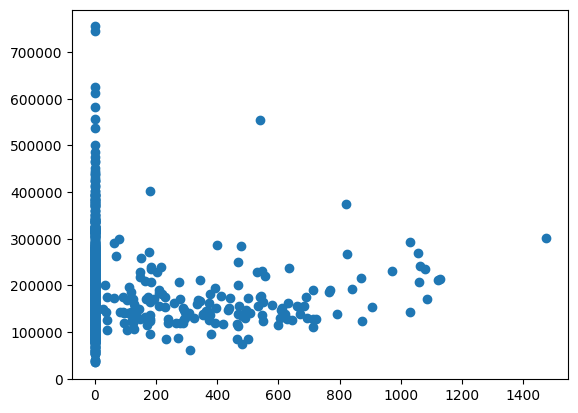

In [ ]:
plt.scatter(x='BsmtFinSF2', y='SalePrice', data=df_train)

In [ ]:
df_train.query('BsmtFinSF2 > 1200')
#323

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
322,323,60,RL,86.0,10380,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,8,2007,WD,Normal,301000


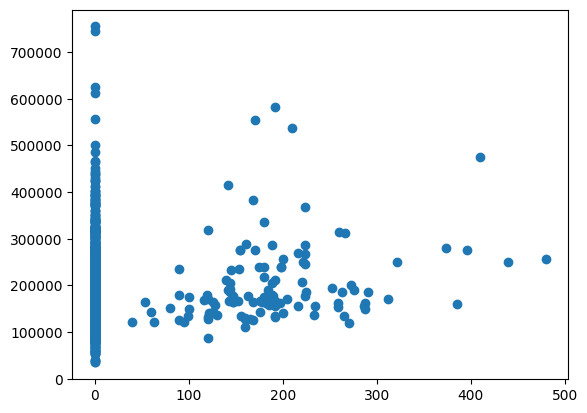

In [ ]:
plt.scatter(x='ScreenPorch', y='SalePrice', data=df_train)

In [ ]:
df_train.query('ScreenPorch > 100 & SalePrice > 450000')
#186, 441	, 770, 804

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
185,186,75,RM,90.0,22950,Pave,NaN,IR2,Lvl,AllPub,...,0,NaN,GdPrv,NaN,0,6,2006,WD,Normal,475000
440,441,20,RL,105.0,15431,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2009,WD,Normal,555000
769,770,60,RL,47.0,53504,Pave,NaN,IR2,HLS,AllPub,...,0,NaN,NaN,NaN,0,6,2010,WD,Normal,538000
803,804,60,RL,107.0,13891,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,1,2009,New,Partial,582933


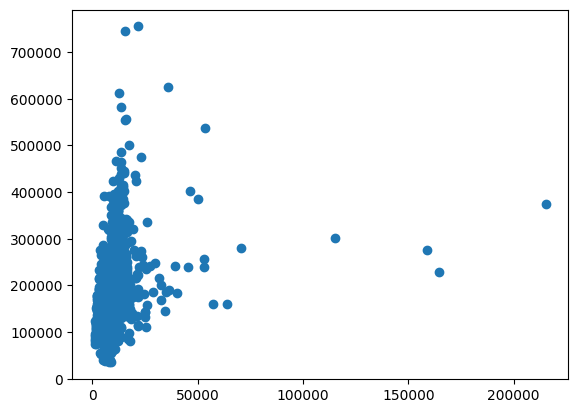

In [ ]:
plt.scatter(x='LotArea', y='SalePrice', data=df_train)

In [ ]:
df_train.query('LotArea > 150000')
#250, 314, 336

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
249,250,50,RL,NaN,159000,Pave,NaN,IR2,Low,AllPub,...,0,NaN,NaN,Shed,500,6,2007,WD,Normal,277000
313,314,20,RL,150.0,215245,Pave,NaN,IR3,Low,AllPub,...,0,NaN,NaN,NaN,0,6,2009,WD,Normal,375000
335,336,190,RL,NaN,164660,Grvl,NaN,IR1,HLS,AllPub,...,0,NaN,NaN,Shed,700,8,2008,WD,Normal,228950


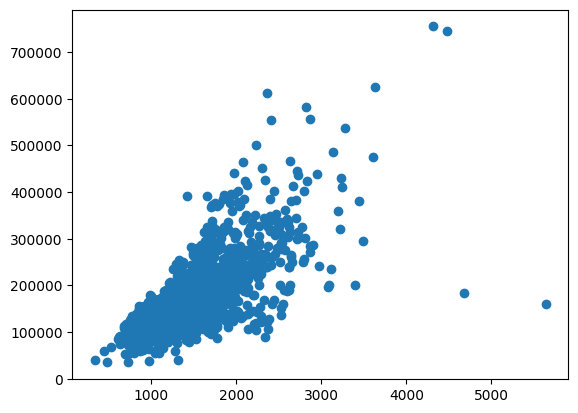

In [ ]:
plt.scatter(x='GrLivArea', y='SalePrice', data=df_train)

In [ ]:
df_train.query('GrLivArea > 4000')
#524, 692, 1183, 1299

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
523,524,60,RL,130.0,40094,Pave,NaN,IR1,Bnk,AllPub,...,0,NaN,NaN,NaN,0,10,2007,New,Partial,184750
691,692,60,RL,104.0,21535,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,1,2007,WD,Normal,755000
1182,1183,60,RL,160.0,15623,Pave,NaN,IR1,Lvl,AllPub,...,555,Ex,MnPrv,NaN,0,7,2007,WD,Abnorml,745000
1298,1299,60,RL,313.0,63887,Pave,NaN,IR3,Bnk,AllPub,...,480,Gd,NaN,NaN,0,1,2008,New,Partial,160000


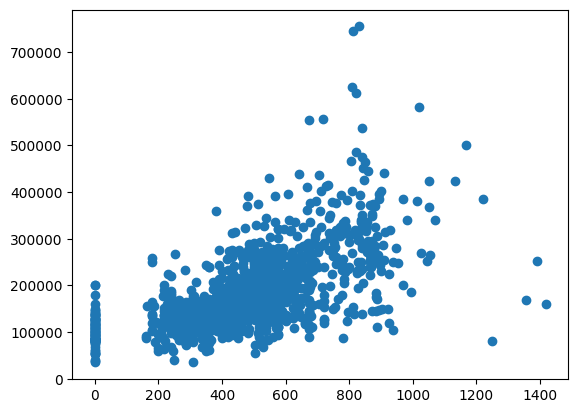

In [ ]:
plt.scatter(x='GarageArea', y='SalePrice', data=df_train)

In [ ]:
df_train.query('GarageArea < 1400 & SalePrice > 700000')
#692, 1183

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
691,692,60,RL,104.0,21535,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,1,2007,WD,Normal,755000
1182,1183,60,RL,160.0,15623,Pave,NaN,IR1,Lvl,AllPub,...,555,Ex,MnPrv,NaN,0,7,2007,WD,Abnorml,745000


In [ ]:
df_train.query('GarageArea > 1200 & SalePrice < 300000')
#581, 1061, 1190, 1298

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
581,582,20,RL,98.0,12704,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2009,New,Partial,253293
1061,1062,30,C (all),120.0,18000,Grvl,NaN,Reg,Low,AllPub,...,0,NaN,NaN,Shed,560,8,2008,ConLD,Normal,81000
1190,1191,190,RL,NaN,32463,Pave,NaN,Reg,Low,AllPub,...,0,NaN,NaN,NaN,0,3,2007,WD,Normal,168000
1298,1299,60,RL,313.0,63887,Pave,NaN,IR3,Bnk,AllPub,...,480,Gd,NaN,NaN,0,1,2008,New,Partial,160000


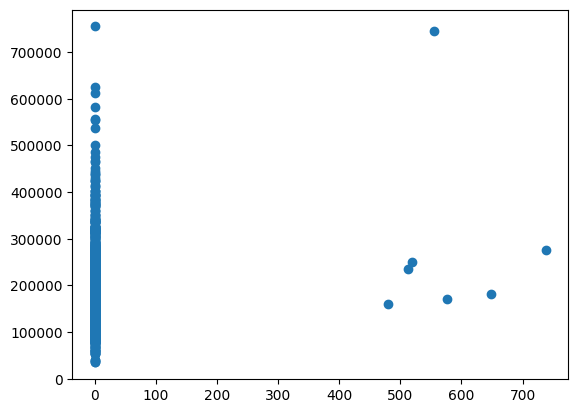

In [ ]:
plt.scatter(x='PoolArea', y='SalePrice', data=df_train)

In [ ]:
val = [581, 1061, 1190, 1298, 692, 1183, 524, 129, 250, 314, 336, 186, 441, 770, 804, 323, 198, 748]
df_train = df_train[df_train.Id.isin(val) == False]

# **Valores Nulos**

In [ ]:
pd.DataFrame(df_train.isnull().sum().sort_values(ascending=False)).head(28)

,0
PoolQC,1437
MiscFeature,1390
Alley,1352
Fence,1165
MasVnrType,864
FireplaceQu,688
LotFrontage,256
GarageQual,81
GarageFinish,81
GarageType,81


In [ ]:
df_train= df_train.drop(columns=['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'GarageYrBlt', 'GarageCond', 'BsmtFinType2'])
df_test= df_test.drop(columns=['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'GarageYrBlt', 'GarageCond', 'BsmtFinType2'])

In [ ]:
df_train.dtypes[df_train.dtypes == 'object']

,0
MSZoning,object
Street,object
LotShape,object
LandContour,object
Utilities,object
LotConfig,object
LandSlope,object
Neighborhood,object
Condition1,object
Condition2,object


# **Feature Engineering**

In [ ]:
df_train['idadeCasa'] = df_train['YrSold'] - df_train['YearBuilt']
df_test['idadeCasa'] = df_test['YrSold'] - df_test['YearBuilt']

In [ ]:
df_train['anosReforma'] = df_train['YrSold'] - df_train['YearRemodAdd']
df_test['anosReforma'] = df_test['YrSold'] - df_test['YearRemodAdd']

In [ ]:
df_train['areaTotal'] = df_train['GrLivArea'] + df_train['TotalBsmtSF'] + df_train['GarageArea']
df_test['areaTotal'] = df_test['GrLivArea'] + df_test['TotalBsmtSF'] + df_test['GarageArea']

In [ ]:
df_train['areaCasaF'] = df_train['1stFlrSF'] + df_train['2ndFlrSF'] + df_train['BsmtFinSF1'] + df_train['BsmtFinSF2']
df_test['areaCasaF'] = df_test['1stFlrSF'] + df_test['2ndFlrSF'] + df_test['BsmtFinSF1'] + df_test['BsmtFinSF2']

In [ ]:
df_train['totalBanheiros'] = df_train['BsmtFullBath'] + df_train['FullBath'] + 0.5 * (df_train['BsmtHalfBath'] + df_train['HalfBath'])
df_test['totalBanheiros'] = df_test['BsmtFullBath'] + df_test['FullBath'] + 0.5 * (df_test['BsmtHalfBath'] + df_test['HalfBath'])

In [ ]:
df_train['areaLazer'] = df_train['WoodDeckSF'] + df_train['OpenPorchSF'] + df_train['EnclosedPorch'] + df_train['3SsnPorch'] + df_train['PoolArea']
df_test['areaLazer'] = df_test['WoodDeckSF'] + df_test['OpenPorchSF'] + df_test['EnclosedPorch'] + df_test['3SsnPorch'] + df_test['PoolArea']

In [ ]:
df_train = df_train.drop(columns=['Id','YrSold','YearBuilt','YearRemodAdd', 'GrLivArea','TotalBsmtSF','GarageArea','1stFlrSF','2ndFlrSF','BsmtFinSF1','BsmtFinSF2','BsmtFullBath', 'FullBath',
'BsmtHalfBath', 'HalfBath', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'PoolArea'])
df_test = df_test.drop(columns=['YrSold','YearBuilt','YearRemodAdd', 'GrLivArea','TotalBsmtSF','GarageArea','1stFlrSF','2ndFlrSF','BsmtFinSF1','BsmtFinSF2','BsmtFullBath', 'FullBath',
'BsmtHalfBath', 'HalfBath', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'PoolArea'])

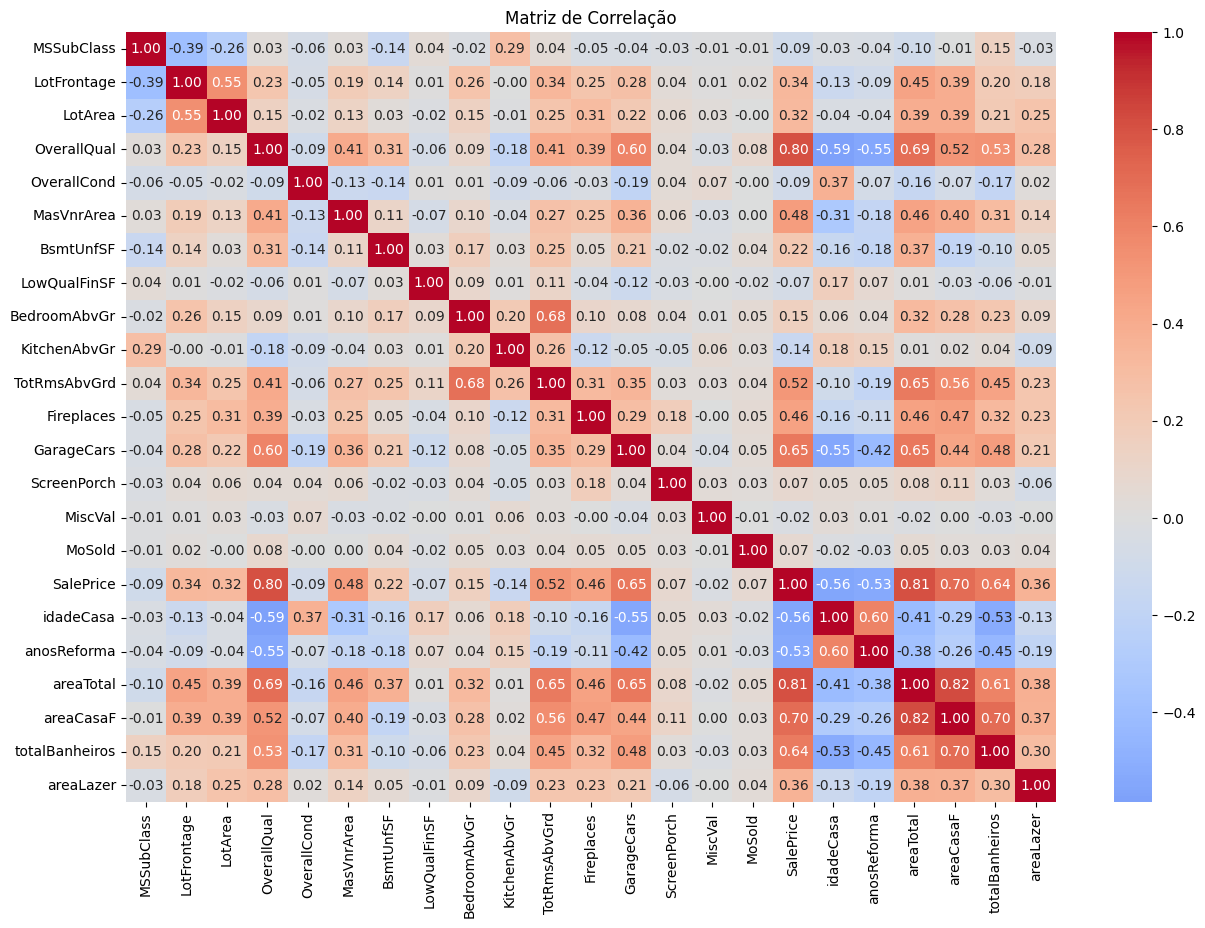

In [ ]:
correlation_matrix = df_train.corr(numeric_only=True)
plt.figure(figsize=(15,10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', center=0)
plt.title('Matriz de Correlação')
plt.show()

In [ ]:
#MSSubClass, OverallCond, LowQualFinSF, ScreenPorch, MiscVal, MoSold

In [ ]:
df_train = df_train.drop(columns=['LowQualFinSF', 'ScreenPorch', 'MiscVal', 'MoSold'])
df_test = df_test.drop(columns=['LowQualFinSF', 'ScreenPorch', 'MiscVal', 'MoSold'])

<Axes: xlabel='SalePrice', ylabel='Count'>

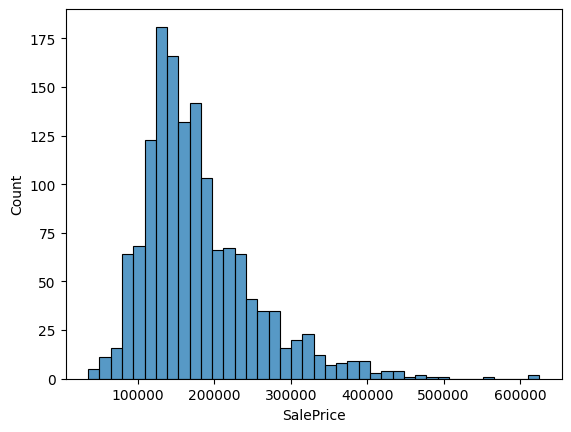

In [ ]:
sns.histplot(df_train, x=df_train['SalePrice'])

<Axes: xlabel='SalePrice', ylabel='Count'>

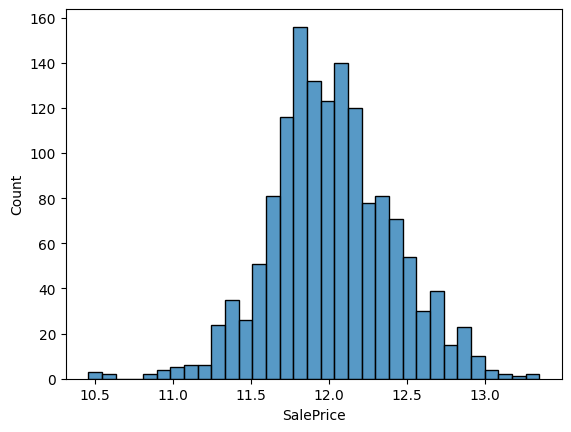

In [ ]:
df_train['SalePrice'] = np.log1p(df_train['SalePrice'])
sns.histplot(df_train, x=df_train['SalePrice'])

# **Pipeline**

In [ ]:
df_train.dtypes[df_train.dtypes == 'object']

,0
MSZoning,object
Street,object
LotShape,object
LandContour,object
Utilities,object
LotConfig,object
LandSlope,object
Neighborhood,object
Condition1,object
Condition2,object


In [ ]:
df_train.dtypes[df_train.dtypes != 'object']

,0
MSSubClass,int64
LotFrontage,float64
LotArea,int64
OverallQual,int64
OverallCond,int64
MasVnrArea,float64
BsmtUnfSF,int64
BedroomAbvGr,int64
KitchenAbvGr,int64
TotRmsAbvGrd,int64


In [ ]:
ord_enc= ['LotShape', 'LandContour', 'LandSlope', 'ExterQual', 'ExterCond','BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'HeatingQC', 'KitchenQual', 'Functional', 'FireplaceQu',
          'GarageFinish', 'GarageQual', 'PavedDrive', 'CentralAir']

In [ ]:
hot_enc= ['MSZoning','Street', 'Utilities', 'LotConfig', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd',
          'MasVnrType','Foundation','Heating', 'CentralAir', 'Electrical', 'GarageType', 'SaleType', 'SaleCondition']

In [ ]:
class Outlier(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.means_ = X.mean()
        self.Q1 = X.quantile(0.25)
        self.Q3 = X.quantile(0.75)
        self.IQR = self.Q3 - self.Q1
        return self

    def transform(self, X):
        X = X.copy()
        lower_bound = self.Q1 - 1.5 * self.IQR
        upper_bound = self.Q3 + 1.5 * self.IQR

        for col in X.columns:
            outliers = (X[col] < lower_bound[col]) | (X[col] > upper_bound[col])
            X.loc[outliers, col] = X[col].median()
        return X

In [ ]:
num_cols = df_train.select_dtypes(include=['int64', 'float64']).columns
num_cols = num_cols.drop('SalePrice')

num_pipeline = Pipeline(steps=[
    ('outlier_handler', Outlier()),
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])


In [ ]:
ord_pipeline = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('ode', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
])

In [ ]:
hot_pipeline = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

In [ ]:
col_trans = ColumnTransformer(transformers=[
    ('num_p', num_pipeline, num_cols),
    ('ord_p', ord_pipeline, ord_enc),
    ('hot_p', hot_pipeline, hot_enc),
    ],
    remainder='passthrough',
    n_jobs=-1)

In [ ]:
X = df_train.drop('SalePrice', axis=1)
y = df_train['SalePrice']

In [ ]:
pipeline = Pipeline(steps=[
    ('preprocessing', col_trans)
])

In [ ]:
X_preprocessed = pipeline.fit_transform(X)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X_preprocessed, y, test_size=0.2, random_state=25)

# **Treinamento**

Linear Regression

In [ ]:
lr = LinearRegression()

In [ ]:
lr.fit(X_train, y_train)

LinearRegression()

In [ ]:
y_pred_lr = lr.predict(X_test)

In [ ]:
mean_squared_error(y_test, y_pred_lr)

0.01737307280316175

Random Forest

In [ ]:
rf = RandomForestRegressor(n_estimators=100, random_state=42)

In [ ]:
rf.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [ ]:
y_pred_rf = rf.predict(X_test)

In [ ]:
mean_squared_error(y_test, y_pred_rf)

0.01901346305005153

XGBoost

In [ ]:
xgb = XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=4, random_state=42)

In [ ]:
xgb.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.05, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=4, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=500, n_jobs=None,
             num_parallel_tree=None, random_state=42, ...)

In [ ]:
y_pred_xgb = xgb.predict(X_test)

In [ ]:
mean_squared_error(y_test, y_pred_xgb)

0.016575127332780184